In [23]:
from langchain_text_splitters import ( CharacterTextSplitter,TokenTextSplitter,RecursiveCharacterTextSplitter,Language )
from langchain_experimental.text_splitter import SemanticChunker
from langchain_openai.embeddings import OpenAIEmbeddings
from dotenv import load_dotenv

C:\Users\RISHABH\AppData\Local\Temp\ipykernel_30876\3886616049.py:2: DeprecationWarning: `langchain-experimental` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-experimental/issues/87 for details.
  from langchain_experimental.text_splitter import SemanticChunker


## TABLE OF CONTENTS 

1)  Length based {chars,tokens based }
2)  text-structure based  
3)  semantic meaning based 


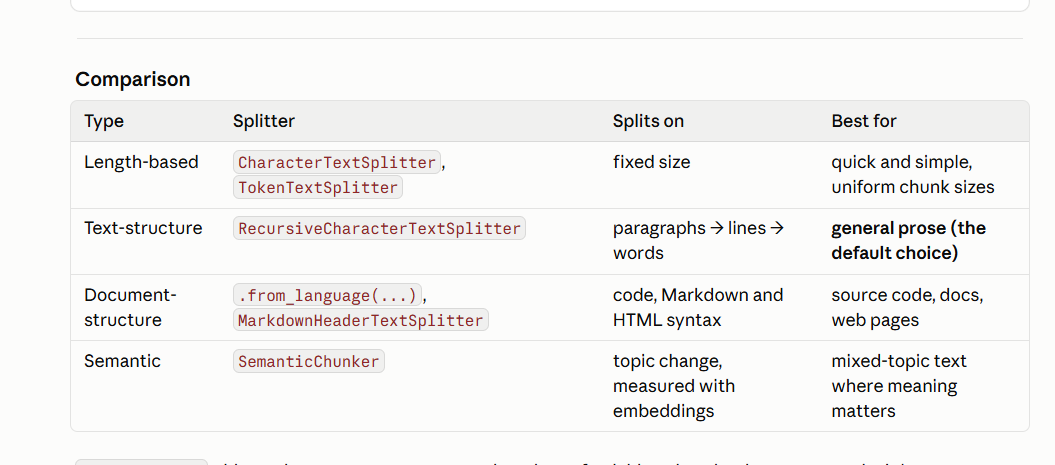

In [16]:
## randoms texts and content

text = """Space exploration has led to incredible scientific discoveries. 
From landing on the Moon to exploring Mars, humanity continues to push the boundaries of what's possible beyond our planet

These missions have not only expanded our knowledge of the universe but have also contributed to advancements in technology here on Earth."""


Markdown_text  =  """
# Project Name: Smart Student Tracker

A simple Python-based project to manage and track student data, including their grades, age, and academic status.


## Features

- Add new students with relevant info
- View student details
- Check if a student is passing
- Easily extendable class-based design


## 🛠 Tech Stack

- Python 3.10+
- No external dependencies


## Getting Started

1. Clone the repo  
   ```bash
   git clone https://github.com/your-username/student-tracker.git

"""

## 1) Length based splitting 

In [ ]:
## by length 


## by character 
character_splitter =  CharacterTextSplitter(chunk_size=10,chunk_overlap=0,separator="") # chunk_size =>  cut after x chars  
splitted =  character_splitter.split_text(text)

print(splitted)


## tokens split 
tokens_splitter  = TokenTextSplitter(chunk_size=10,chunk_overlap=0) # chunk_size  => cut after x words 
tokens =  tokens_splitter.split_text(text)

print(tokens)


['Space expl', 'oration ha', 's led to i', 'ncredible', 'scientific', 'discoveri', 'es. From l', 'anding on', 'the Moon t', 'o explorin', 'g Mars, hu', 'manity con', 'tinues to', 'push the b', 'oundaries', "of what's", 'possible b', 'eyond our', 'planet.\n\nT', 'hese missi', 'ons have n', 'ot only ex', 'panded our', 'knowledge', 'of the un', 'iverse but', 'have also', 'contribut', 'ed to adva', 'ncements i', 'n technolo', 'gy here on', 'Earth.']
['Space exploration has led to incredible scientific discoveries. From', ' landing on the Moon to exploring Mars, humanity continues', " to push the boundaries of what's possible beyond our", ' planet.\n\nThese missions have not only expanded', ' our knowledge of the universe but have also contributed to', ' advancements in technology here on Earth.']


## 2)  Text Structure based 

In [21]:
text_structure_splitter  =  RecursiveCharacterTextSplitter.from_language(chunk_size=200,chunk_overlap=0,language=Language.MARKDOWN)

words =  text_structure_splitter.split_text(Markdown_text)
print(words)

['# Project Name: Smart Student Tracker\n\nA simple Python-based project to manage and track student data, including their grades, age, and academic status.', '## Features\n\n- Add new students with relevant info\n- View student details\n- Check if a student is passing\n- Easily extendable class-based design', '## 🛠 Tech Stack\n\n- Python 3.10+\n- No external dependencies\n\n\n## Getting Started\n\n1. Clone the repo  \n   ```bash\n   git clone https://github.com/your-username/student-tracker.git']


## 3)  Semantic meaning Structure based 

In [24]:

semantic_spliiter = SemanticChunker(
    OpenAIEmbeddings(), breakpoint_threshold_type="standard_deviation",
    breakpoint_threshold_amount=3
)


docs = semantic_spliiter.create_documents([Markdown_text])

print(docs)

[Document(metadata={}, page_content='\n# Project Name: Smart Student Tracker\n\nA simple Python-based project to manage and track student data, including their grades, age, and academic status. ## Features\n\n- Add new students with relevant info\n- View student details\n- Check if a student is passing\n- Easily extendable class-based design\n\n\n## 🛠 Tech Stack\n\n- Python 3.10+\n- No external dependencies\n\n\n## Getting Started\n\n1. Clone the repo  \n   ```bash\n   git clone https://github.com/your-username/student-tracker.git\n\n')]
